# 04 – Synthesis: profitability, volatility, debt-carrying capacity and risk map (H3 volatility part + H4)

**Hypotheses:**
> **H3 (Branch 3):** The new businesses (international white cement, building materials) did not raise the overall gross margin, but made revenue more FX-denominated and less volatile. Test: segment margins and mix effect; margin volatility before and after the transformation.

> **H4 (Synthesis):** Compared with 2016, Çimsa is more resilient to FX and energy shocks, but part of the risk has shifted to borrowing. The success of the transformation depends on how well FX revenue covers FX debt. Test: net debt/EBITDA, FX revenue/debt ratio, margin volatility.

**Data:** Only `output/tables/` (annual_master, quarterly_series, quarterly_ratios_tms29, fx_debt_annual, fx_rates_annual). No PDFs are read.

### Results of the previous notebooks

**01 – Energy (H2, price side):**
- The share of energy in production cost fell from its 60% peak in 2022 to 21% in 2025.
- The decline in energy cost after 2022 comes mainly together with the price effect; physical consumption is flat.
- Çimsa's implied energy price tracks the market with a lag and in a smoothed way: it rose much less than the market in 2022 and fell less afterwards. This pattern holds under both base years.
- There is no lasting, company-specific advantage on the price side. Smoothing does not remove the burden of the shock; it spreads it over time.

**02 – Cost structure and mix (H2 in full, H3 margin part):**
- About half of the 2022 → 2025 decline in the energy share comes together with the real decline in energy cost, and half with growth in the denominator (other production, raw material). ~16% may be related to the 2025 classification change.
- No lasting improvement in physical energy intensity. H2: **partially**.
- The 2022 → 2025 increase in gross margin (+8.2 points) is almost entirely within segments (cement margin). The contribution of building materials is ~−1.1 points; its margin is below cement's. H3 margin part: **confirmed**.

**03 – FX risk (H1):**
- FX revenue was not enough to prevent the margin from falling in shock quarters; without a peer company, how the margin would have developed without FX revenue cannot be known.
- The share of FX loans rose from 15% (2016) to 87% (2025); FX loans / EBITDA proxy 2.7x (2025).
- The net FX position of the companies in Turkey has been balanced or a net asset since 2017. The FX risk lies in the debt-carrying capacity of the foreign companies.
- H1: **partially**.

## Setup: loading data and helpers

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "output" / "tables"
FIGS = ROOT / "output" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)

C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
C_GREY, C_INK, C_MUTED = "#8a8985", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False,
})
YEARS = list(range(2016, 2026))
SCOPE = [(2017, "USA"), (2021, "international\nto SBS"), (2022, "Central Anatolia\nsale"), (2023, "SBS\ncontrol"), (2024, "Mannok\n(Q4)")]

def mark_breaks(ax, scope=True, label=True):
    ax.axvline(2022.5, color=C_MUTED, linestyle="--", linewidth=1)
    if label:
        ax.text(2022.55, 0.98, "IAS 29 →", transform=ax.get_xaxis_transform(), fontsize=7.5, color=C_MUTED, va="top")
    if scope:
        for y, t in SCOPE:
            ax.plot(y, 0.0, marker="^", markersize=6, color=C_GREY, transform=ax.get_xaxis_transform(), clip_on=False)

def mark_2024(ax):
    ax.axvspan(2023.6, 2024.4, color=C_YELLOW, alpha=0.15, linewidth=0)

In [2]:
master = pd.read_csv(TABLES / "annual_master.csv")
own = master[(master["view"] == "own") & master["year"].between(2016, 2025)].set_index("year").sort_index()
r2022 = master[(master["year"] == 2022) & (master["view"] == "restated_in_2023")].iloc[0]
qnom = pd.read_csv(TABLES / "quarterly_series.csv")
qtms = pd.read_csv(TABLES / "quarterly_ratios_tms29.csv")
fxd = pd.read_csv(TABLES / "fx_debt_annual.csv")
fxd["report_year"] = fxd["source_file"].str.extract(r"(\d{4})_12", expand=False).astype(int)
rates = pd.read_csv(TABLES / "fx_rates_annual.csv")
usd_end = rates[(rates["item"] == "fx_usd_try_period_end") & (rates["period"] == "FY")].set_index("year")["value"]

def fxv(item, year, report_year=None):
    r = fxd[(fxd["item"] == item) & (fxd["year"] == year) & (fxd["report_year"] == (report_year or year))]
    return r["value"].iloc[0] if len(r) else np.nan
print(f"own: {len(own)} years; nominal quarters: {(qnom['item'] == 'gross_margin').sum()}; IAS 29 quarterly ratio rows: {(qtms['use'] == 'analysis').sum()}")

own: 10 years; nominal quarters: 31; IAS 29 quarterly ratio rows: 27


## 1. Profitability level (2016–2025)

- **Indicators:** Gross margin and EBITDA proxy margin (`ebitda_proxy / revenue`); also gross profit and EBITDA proxy in dollars.
- **FX conversion:** Annual average rate in nominal years, year-end rate in IAS 29 years.
- **Comparison warning:** The margin level of IAS 29 years cannot be compared one-to-one with nominal years. The two versions of 2022 illustrate this: gross margin 17.2% (nominal) and 11.4% (IAS 29 + SBS); shown with a hollow marker.
- **Dollar conversion limit:** In IAS 29 years dollar amounts may be slightly biased upwards.
- **EBITDA proxy:** Operating profit + depreciation; not the reported EBITDA.

In [3]:
prof = pd.DataFrame({
    "basis": own["basis"],
    "gross_margin_pct": own["gross_margin"] * 100,
    "ebitda_proxy_margin_pct": own["ebitda_proxy"] / own["revenue"] * 100,
    "gross_profit_mn_usd": own["gross_profit_usd"] / 1e6,
    "ebitda_proxy_mn_usd": own["ebitda_proxy_usd"] / 1e6,
    "revenue_mn_usd": own["revenue_usd"] / 1e6,
})
print(f"2022 (IAS 29 + SBS): gross margin {r2022['gross_margin']*100:.1f}%, EBITDA proxy margin {r2022['ebitda_proxy']/r2022['revenue']*100:.1f}%")
prof.round(1)

2022 (IAS 29 + SBS): gross margin 11.4%, EBITDA proxy margin 12.6%


,basis,gross_margin_pct,ebitda_proxy_margin_pct,gross_profit_mn_usd,ebitda_proxy_mn_usd,revenue_mn_usd
year,,,,,,
2016,nominal,32.1,31.2,124.3,120.7,387.4
2017,nominal,26.5,27.6,108.3,112.8,408.9
2018,nominal,23.9,25.0,84.5,88.4,353.9
2019,nominal,17.6,17.8,53.6,54.1,304.4
2020,nominal,22.5,23.9,66.7,70.7,296.2
2021,nominal,19.0,23.4,80.2,98.6,421.5
2022,nominal,17.2,17.0,89.3,88.0,518.1
2023,tms29,19.7,22.0,137.1,153.2,697.5
2024,tms29,21.5,19.6,171.6,156.3,799.2


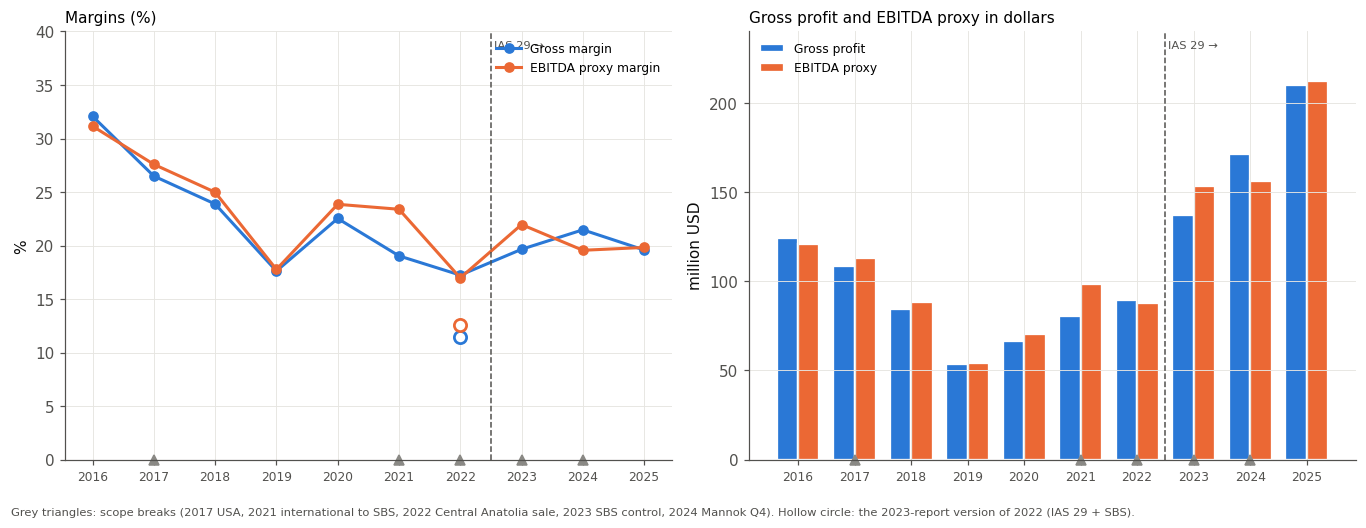

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
ax.plot(YEARS, prof["gross_margin_pct"], marker="o", color=C_BLUE, label="Gross margin")
ax.plot(YEARS, prof["ebitda_proxy_margin_pct"], marker="o", color=C_ORANGE, label="EBITDA proxy margin")
ax.plot(2022, r2022["gross_margin"] * 100, marker="o", markersize=8, markerfacecolor="white", markeredgecolor=C_BLUE, markeredgewidth=1.8, linestyle="none")
ax.plot(2022, r2022["ebitda_proxy"] / r2022["revenue"] * 100, marker="o", markersize=8, markerfacecolor="white", markeredgecolor=C_ORANGE, markeredgewidth=1.8, linestyle="none")
ax.set_ylim(0, 40); ax.set_ylabel("%")
ax.set_title("Margins (%)", loc="left", fontsize=10)
ax.legend(loc="upper right", fontsize=8)
ax = axes[1]
w = 0.38
ax.bar(np.array(YEARS) - w / 2, prof["gross_profit_mn_usd"], width=w, color=C_BLUE, edgecolor="white", linewidth=1.5, label="Gross profit")
ax.bar(np.array(YEARS) + w / 2, prof["ebitda_proxy_mn_usd"], width=w, color=C_ORANGE, edgecolor="white", linewidth=1.5, label="EBITDA proxy")
ax.set_ylim(0, 240); ax.set_ylabel("million USD")
ax.set_title("Gross profit and EBITDA proxy in dollars", loc="left", fontsize=10)
ax.legend(loc="upper left", fontsize=8)
for ax in axes:
    ax.set_xticks(YEARS); ax.tick_params(axis="x", labelsize=8)
    mark_breaks(ax)
fig.text(0.01, -0.03, "Grey triangles: scope breaks (2017 USA, 2021 international to SBS, 2022 Central Anatolia sale, 2023 SBS control, 2024 Mannok Q4). "
         "Hollow circle: the 2023-report version of 2022 (IAS 29 + SBS).", fontsize=7.5, color=C_MUTED)
fig.tight_layout()
fig.savefig(FIGS / "04_profitability_level.png", bbox_inches="tight")
plt.show()

**What we see:**
- **Margins:** Gross margin is 32% in 2016. It falls to 18% in 2019 and is in the 17–23% band in 2020–2025 (2025: 19.6%). The EBITDA proxy margin follows a similar path (2016: 31%, 2025: 20%).
- **Dollar amounts:** Gross profit and the EBITDA proxy rise from the 2019 trough (~54 million USD) to ~210 million USD in 2025; ~1.7 times 2016 (~120 million USD). This increase comes together with the widening of the consolidation scope (SBS, Mannok).
- **Reading:** The margin level is below 2016 and close to the 2019–2023 average. Absolute profit, however, has grown markedly.

## 2. Margin volatility (H3, volatility part)

Quarterly gross margin, three periods:

| Period | Quarters | Source |
|---|---|---|
| Pre-transformation | 2016 Q1 – 2019 Q4 (16) | `quarterly_series.csv`, `value_preferred` |
| Crisis and transition | 2020 Q1 – 2023 Q3 (15) | `quarterly_series.csv`, `value_preferred` |
| Post-transformation | 2023 Q4 – 2025 Q4 (9) | `quarterly_ratios_tms29.csv`, `use = analysis` |

**Measures:**
- Standard deviation and min–max range.
- To remove seasonality, the standard deviation of the change versus the same quarter of the previous year. This change is only computed within the same series; a nominal quarter is not compared with an IAS 29 quarter. That is why there are only 5 values in the post-transformation period (2024 Q4, 2025 Q1–Q4).

**Choice of gross margin:** The comparison uses gross margin. 2024 Q4 energy ratios are not used because of the classification shift and the Mannok consolidation; the 2025 interim reports use the new energy classification. Gross margin is not affected by classification between cost items.

**Limitations:**
- **(a) Short period without shocks:** The post-transformation period is only 9 quarters and contains no major shock (energy prices were falling). Low volatility may also result from the absence of shocks rather than from the transformation.
- **(b) No level comparison:** The IAS 29 gross margin differs in level from the nominal one (2022: 17.2% nominal, 11.4% IAS 29). Only volatility (dispersion) is compared across periods.
- **(c) 2023 Q4:** The value is approximate; the nominal 9 months were rolled forward to December 2023 purchasing power with the CPI.
- **(d) Series mixing:** The volatility comparison puts the nominal and IAS 29 series side by side. This is the only series mixing, done with the limitations above.

In [5]:
qn = qnom[qnom["item"] == "gross_margin"][["year", "period", "value_preferred"]].rename(columns={"value_preferred": "gm"})
qn["basis"] = "nominal"
qt = qtms[(qtms["use"] == "analysis") & (qtms["item"] == "gross_margin")][["year", "period", "value"]].rename(columns={"value": "gm"})
qt["basis"] = "tms29"
qs = pd.concat([qn, qt]).sort_values(["year", "period"]).reset_index(drop=True)
qs["gm"] *= 100
qs["q"] = qs["period"].str[1].astype(int)
qs["label"] = qs["year"].astype(str) + " Q" + qs["q"].astype(str)

def period_of(y, q):
    k = y * 10 + q
    return "1. Pre-transformation (2016 Q1–2019 Q4)" if k <= 20194 else (
        "2. Crisis and transition (2020 Q1–2023 Q3)" if k <= 20233 else "3. Post-transformation (2023 Q4–2025 Q4)")
qs["phase"] = [period_of(y, q) for y, q in zip(qs["year"], qs["q"])]
# change versus the same quarter of the previous year: only within the same series (basis)
lookup = qs.set_index(["year", "q", "basis"])["gm"]
qs["yoy_pp"] = [g - lookup.get((y - 1, q, b), np.nan) for y, q, b, g in zip(qs["year"], qs["q"], qs["basis"], qs["gm"])]
qs["approx"] = (qs["year"] == 2023) & (qs["q"] == 4)

vol = qs.groupby("phase").agg(
    quarters=("gm", "size"), mean_pct=("gm", "mean"), std_pp=("gm", "std"), min_pct=("gm", "min"), max_pct=("gm", "max"),
    yoy_n=("yoy_pp", "count"), yoy_std_pp=("yoy_pp", "std"))
vol["range_pp"] = vol["max_pct"] - vol["min_pct"]
vol = vol[["quarters", "std_pp", "min_pct", "max_pct", "range_pp", "yoy_n", "yoy_std_pp", "mean_pct"]]
vol.round(2)

,quarters,std_pp,min_pct,max_pct,range_pp,yoy_n,yoy_std_pp,mean_pct
phase,,,,,,,,
1. Pre-transformation (2016 Q1–2019 Q4),16,6.72,13.57,37.35,23.78,12,6.28,24.83
2. Crisis and transition (2020 Q1–2023 Q3),15,5.32,13.03,29.01,15.98,15,7.45,20.53
3. Post-transformation (2023 Q4–2025 Q4),9,5.94,13.31,29.91,16.59,5,5.67,20.00


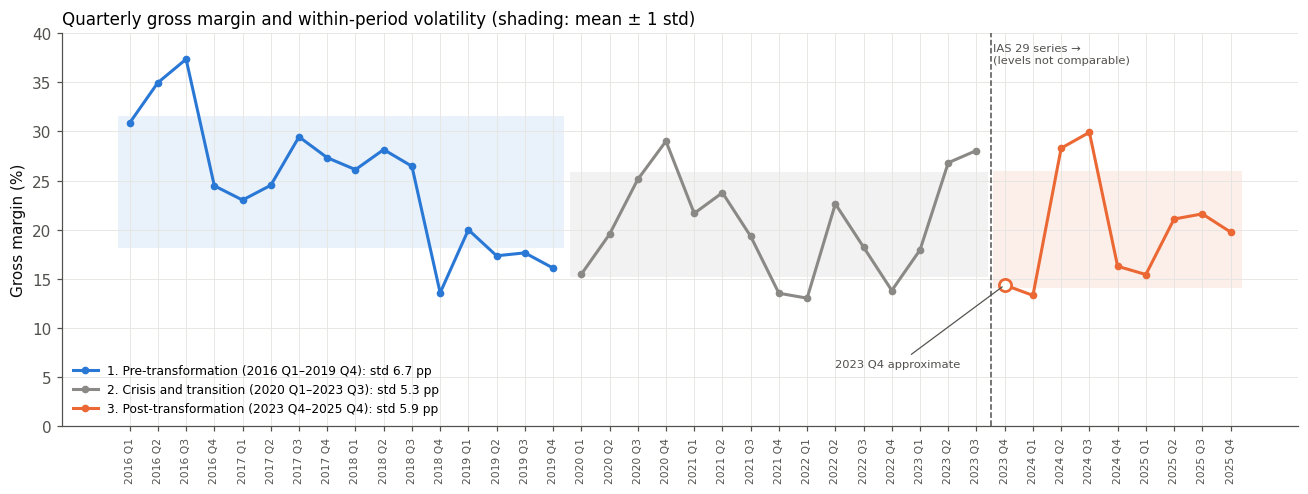

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.6))
x = np.arange(len(qs))
PH_COL = {p: c for p, c in zip(sorted(qs["phase"].unique()), [C_BLUE, C_GREY, C_ORANGE])}
for p, g in qs.groupby("phase"):
    ax.plot(g.index, g["gm"], marker="o", markersize=4, color=PH_COL[p], label=f"{p}: std {vol.loc[p, 'std_pp']:.1f} pp")
    m = vol.loc[p, "mean_pct"]; s = vol.loc[p, "std_pp"]
    ax.fill_between([g.index.min() - 0.4, g.index.max() + 0.4], m - s, m + s, color=PH_COL[p], alpha=0.10, linewidth=0)
i23 = qs.index[qs["approx"]][0]
ax.plot(i23, qs.loc[i23, "gm"], marker="o", markersize=8, markerfacecolor="white", markeredgecolor=C_ORANGE, markeredgewidth=1.8, linestyle="none")
ax.annotate("2023 Q4 approximate", (i23, qs.loc[i23, "gm"]), xytext=(i23 - 6, 6), fontsize=7.5, color=C_MUTED,
            arrowprops=dict(arrowstyle="-", color=C_MUTED, linewidth=0.8))
ib = qs.index[qs["basis"] == "tms29"].min()
ax.axvline(ib - 0.5, color=C_MUTED, linestyle="--", linewidth=1)
ax.text(ib - 0.4, 39, "IAS 29 series →\n(levels not comparable)", fontsize=7.5, color=C_MUTED, va="top")
ax.set_xticks(x); ax.set_xticklabels(qs["label"], rotation=90, fontsize=7)
ax.set_ylim(0, 40); ax.set_ylabel("Gross margin (%)")
ax.set_title("Quarterly gross margin and within-period volatility (shading: mean ± 1 std)", loc="left", fontsize=11)
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "04_margin_volatility.png", bbox_inches="tight")
plt.show()

**What we see:**

| Measure | Pre-transformation | Crisis and transition | Post-transformation |
|---|---|---|---|
| Gross margin standard deviation | 6.7 points | 5.3 points | 5.9 points |
| Min–max range | 23.8 points | 16.0 points | 16.6 points |
| Std of change vs previous year | 6.3 (12 values) | 7.5 (15 values) | 5.7 (5 values) |

- **Reading:** Post-transformation volatility is slightly lower than pre-transformation and slightly higher than in the crisis period. The differences are small; the post-transformation period is short at 9 quarters and contains no major shock. With this data the conclusion "the margin became less volatile" cannot be reached.

## 3. Debt-carrying capacity (H4), 2016–2025

Definitions are the same as in notebook 03 and the annual_master dictionary:

| Indicator | Definition |
|---|---|
| Net debt / EBITDA proxy | `net_debt_to_ebitda`; net debt = total financial debt (incl. leases) − cash. TRY / TRY, in the same purchasing power. |
| FX loans / EBITDA proxy | EUR + USD + other loans, excluding leases, own report. In USD at the EVDS year-end rate; EBITDA proxy `ebitda_proxy_usd`. |
| FX loans / export sales | The same FX loans; export sales in USD at the annual average rate in nominal years and the year-end rate in IAS 29 years. |
| Interest cover | EBITDA proxy / finance costs (income statement). |

**Notes:**
- In Turkey finance costs may include FX losses as well as interest; "interest cover" is therefore an approximate indicator.
- 2024 ratios may be biased upwards because of Mannok: debt full year, revenue and profit only Q4. Marked in the chart; **main post-transformation year 2025**.

In [7]:
fx_loans_try = pd.Series({y: sum(fxv(f"debt_{c}_try", y) for c in ("eur", "usd", "other")) for y in YEARS})
cap = pd.DataFrame({
    "net_debt_mn_try": own["net_debt"] / 1e6,
    "ebitda_proxy_mn_try": own["ebitda_proxy"] / 1e6,
    "net_debt_to_ebitda": own["net_debt_to_ebitda"],
    "fx_loans_mn_usd": fx_loans_try / usd_end.reindex(YEARS) / 1e6,
    "ebitda_proxy_mn_usd": own["ebitda_proxy_usd"] / 1e6,
    "export_sales_mn_usd": own["revenue_export"] / own["usd_try_rate_used"] / 1e6,
    "finance_costs_mn_try": own["finance_costs"] / 1e6,
})
cap["fx_loans_to_ebitda"] = cap["fx_loans_mn_usd"] / cap["ebitda_proxy_mn_usd"]
cap["fx_loans_to_export_sales"] = cap["fx_loans_mn_usd"] / cap["export_sales_mn_usd"]
cap["interest_cover"] = cap["ebitda_proxy_mn_try"] / cap["finance_costs_mn_try"]
cap.round(2)

,net_debt_mn_try,ebitda_proxy_mn_try,net_debt_to_ebitda,fx_loans_mn_usd,ebitda_proxy_mn_usd,export_sales_mn_usd,finance_costs_mn_try,fx_loans_to_ebitda,fx_loans_to_export_sales,interest_cover
2016,754.19,364.65,2.07,33.74,120.70,131.08,37.07,0.28,0.26,9.84
2017,1172.53,411.21,2.85,116.74,112.81,153.96,102.32,1.03,0.76,4.02
2018,1263.04,424.70,2.97,137.84,88.42,181.00,218.19,1.56,0.76,1.95
2019,1433.82,306.71,4.67,145.20,54.09,202.25,277.87,2.68,0.72,1.10
2020,656.94,495.28,1.33,109.26,70.66,164.21,253.08,1.55,0.67,1.96
2021,1101.56,876.07,1.26,65.89,98.60,259.37,321.20,0.67,0.25,2.73
2022,1245.00,1456.91,0.85,58.53,87.96,287.21,355.08,0.67,0.20,4.10
2023,2339.98,4503.40,0.52,186.10,153.19,293.86,1909.50,1.21,0.63,2.36
2024,13802.73,5505.84,2.51,517.09,156.31,477.46,2420.21,3.31,1.08,2.27
2025,19481.62,9100.67,2.14,568.26,212.32,756.33,2284.56,2.68,0.75,3.98


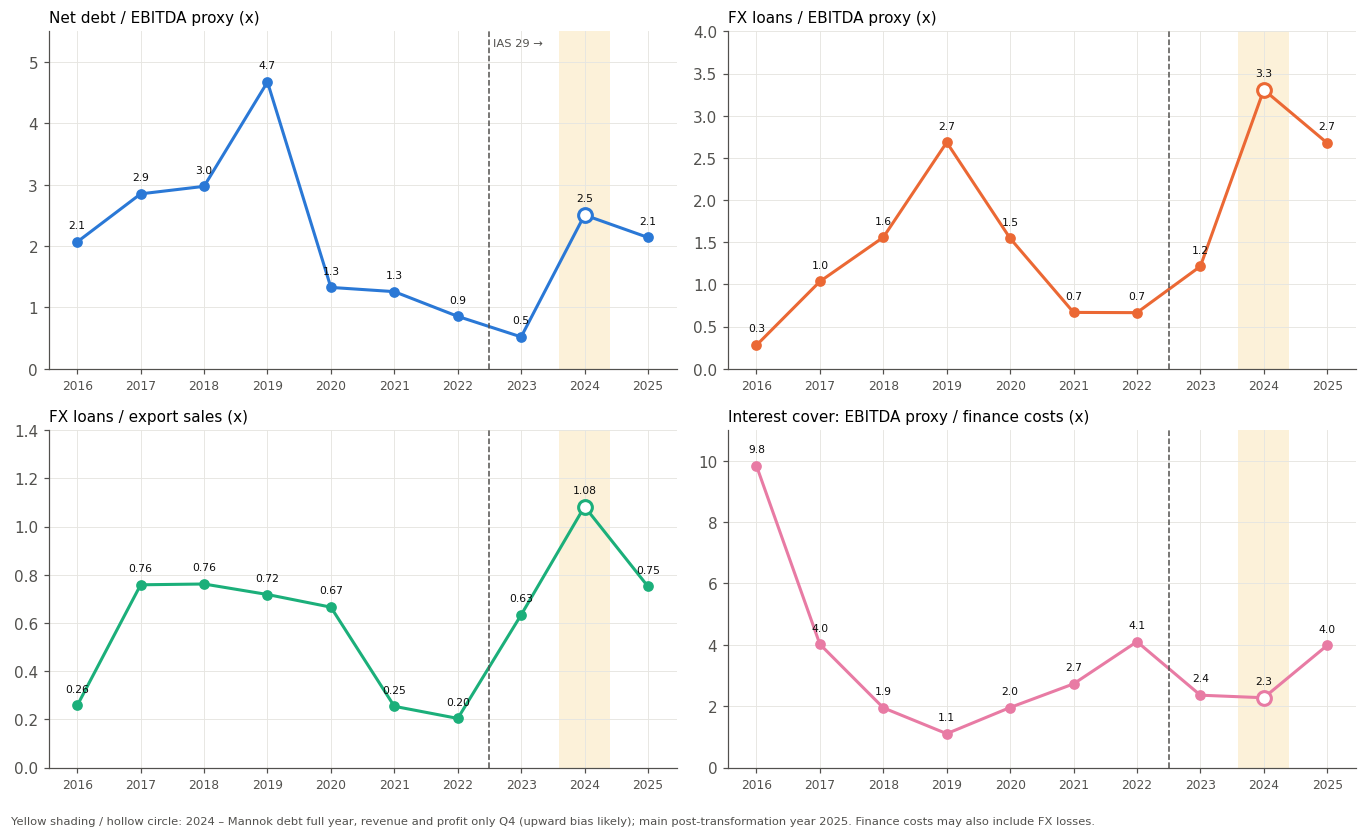

In [8]:
PANELS = [("net_debt_to_ebitda", "Net debt / EBITDA proxy (x)", C_BLUE, (0, 5.5)),
          ("fx_loans_to_ebitda", "FX loans / EBITDA proxy (x)", C_ORANGE, (0, 4)),
          ("fx_loans_to_export_sales", "FX loans / export sales (x)", C_AQUA, (0, 1.4)),
          ("interest_cover", "Interest cover: EBITDA proxy / finance costs (x)", C_MAGENTA, (0, 11))]
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.4))
for ax, (col, title, c, yl) in zip(axes.ravel(), PANELS):
    mark_2024(ax)
    ax.plot(YEARS, cap[col], marker="o", color=c)
    ax.plot(2024, cap.loc[2024, col], marker="o", markersize=9, markerfacecolor="white", markeredgecolor=c, markeredgewidth=2, linestyle="none")
    for y in YEARS:
        ax.text(y, cap.loc[y, col] + (yl[1] - yl[0]) * 0.04, f"{cap.loc[y, col]:.1f}" if yl[1] > 2 else f"{cap.loc[y, col]:.2f}",
                ha="center", fontsize=7, color=C_INK)
    ax.set_ylim(*yl)
    ax.set_xticks(YEARS); ax.tick_params(axis="x", labelsize=8)
    ax.set_title(title, loc="left", fontsize=10)
    mark_breaks(ax, scope=False, label=(ax is axes[0, 0]))
fig.text(0.01, -0.02, "Yellow shading / hollow circle: 2024 – Mannok debt full year, revenue and profit only Q4 (upward bias likely); "
         "main post-transformation year 2025. Finance costs may also include FX losses.", fontsize=7.5, color=C_MUTED)
fig.tight_layout()
fig.savefig(FIGS / "04_debt_capacity.png", bbox_inches="tight")
plt.show()

**What we see:**
- **Net debt / EBITDA proxy:** 2.1x in 2016. A 4.7x peak in 2019, a 0.5x trough in 2023; 2.1x in 2025. Overall leverage is close to 2016.
- **FX loans / EBITDA proxy:** 0.3x (2016) → 2.7x (2025). The currency composition of leverage has changed: most of the debt is now in FX.
- **FX loans / export sales:** 0.26 (2016) → 0.75 (2025). FX debt is below one year of export sales.
- **Interest cover:** 9.8x (2016) → 1.1x trough in 2019 → 4.0x in 2025.

## 4. Risk map

For each risk: pre-transformation (mainly 2016; 2016–2019 where needed) and post-transformation (2025) indicators, the direction of change and the source of evidence.

**Note on the carbon row:** The carbon liability was verified from the short-term provisions note of the 2025 Q1 report: `Data/FinancialStatements/2025/Cimsa_2025_03.pdf`, page 37, "Karbon yükümlülükleri" (carbon liabilities) TRY 2,663,667 thousand (31.12.2024: TRY 2,718,810 thousand); footnote: "CBS B.V.'nin karbon yükümlülüklerinden oluşmaktadır." (consists of the carbon liabilities of CBS B.V.). Buñol (Spain) and Mannok (Ireland) are within the EU Emissions Trading System (EU ETS). The value was not extracted into the `output/tables/` tables; it is used only as context.

In [9]:
risk = pd.DataFrame([
    {"risk": "Energy – cost share",
     "before": "Energy / production cost 33–36% (2016–2019)",
     "after": "21% (2025); ~half of the decline is denominator growth, ~16% classification change",
     "direction": "unclear",
     "evidence": "01 (section 2), 02 (sections 2, 4c)"},
    {"risk": "Energy – price and intensity",
     "before": "Implied price 14 USD/MWh (2020); MWh/ton clinker ~1.1",
     "after": "23 USD/MWh (2025), tracks the market with a lag/smoothed; MWh/ton clinker ~1.15",
     "direction": "unchanged",
     "evidence": "01 (sections 3, 5, 6), 02 (section 3)"},
    {"risk": "FX – revenue side",
     "before": "Export sales share 31% (2016)",
     "after": "64% (2025; incl. subsidiaries abroad); margin fall in shock quarters not prevented",
     "direction": "unclear",
     "evidence": "03 (sections 1, 2)"},
    {"risk": "FX – Turkish balance sheet",
     "before": "Net FX position −31 million USD (2016)",
     "after": "+20 million USD (2025); FX financial liabilities covered by derivatives",
     "direction": "decreased",
     "evidence": "03 (section 4b)"},
    {"risk": "Debt – leverage and currency",
     "before": "Net debt/EBITDA 2.1; FX loan share 15%; FX loans/EBITDA 0.3 (2016)",
     "after": "Net debt/EBITDA 2.1; FX loan share 87%; FX loans/EBITDA 2.7 (2025)",
     "direction": "increased",
     "evidence": "03 (sections 3, 4a), 04 (section 3)"},
    {"risk": "Debt – interest cover",
     "before": "EBITDA proxy / finance costs 9.8 (2016)",
     "after": "4.0 (2025)",
     "direction": "increased (cover weakened)",
     "evidence": "04 (section 3)"},
    {"risk": "Margin volatility",
     "before": "Quarterly gross margin std 6.7 points (2016–2019)",
     "after": "5.9 points (2023 Q4–2025 Q4; 9 quarters, no-shock period)",
     "direction": "unclear",
     "evidence": "04 (section 2)"},
    {"risk": "Carbon",
     "before": "Operations mainly in Turkey; EU ETS exposure not measured in this project",
     "after": "Buñol and Mannok within EU ETS; ~TRY 2.66 billion carbon liability in 2025 Q1 (CBS B.V.)",
     "direction": "increased",
     "evidence": "2025 Q1 report p. 37"},
]).set_index("risk")
risk.columns = ["Pre-transformation", "Post-transformation", "Direction", "Evidence (notebook)"]
risk

,Pre-transformation,Post-transformation,Direction,Evidence (notebook)
risk,,,,
Energy – cost share,Energy / production cost 33–36% (2016–2019),"21% (2025); ~half of the decline is denominator growth, ~16% classification change",unclear,"01 (section 2), 02 (sections 2, 4c)"
Energy – price and intensity,Implied price 14 USD/MWh (2020); MWh/ton clinker ~1.1,"23 USD/MWh (2025), tracks the market with a lag/smoothed; MWh/ton clinker ~1.15",unchanged,"01 (sections 3, 5, 6), 02 (section 3)"
FX – revenue side,Export sales share 31% (2016),64% (2025; incl. subsidiaries abroad); margin fall in shock quarters not prevented,unclear,"03 (sections 1, 2)"
FX – Turkish balance sheet,Net FX position −31 million USD (2016),+20 million USD (2025); FX financial liabilities covered by derivatives,decreased,03 (section 4b)
Debt – leverage and currency,Net debt/EBITDA 2.1; FX loan share 15%; FX loans/EBITDA 0.3 (2016),Net debt/EBITDA 2.1; FX loan share 87%; FX loans/EBITDA 2.7 (2025),increased,"03 (sections 3, 4a), 04 (section 3)"
Debt – interest cover,EBITDA proxy / finance costs 9.8 (2016),4.0 (2025),increased (cover weakened),04 (section 3)
Margin volatility,Quarterly gross margin std 6.7 points (2016–2019),"5.9 points (2023 Q4–2025 Q4; 9 quarters, no-shock period)",unclear,04 (section 2)
Carbon,Operations mainly in Turkey; EU ETS exposure not measured in this project,Buñol and Mannok within EU ETS; ~TRY 2.66 billion carbon liability in 2025 Q1 (CBS B.V.),increased,2025 Q1 report p. 37


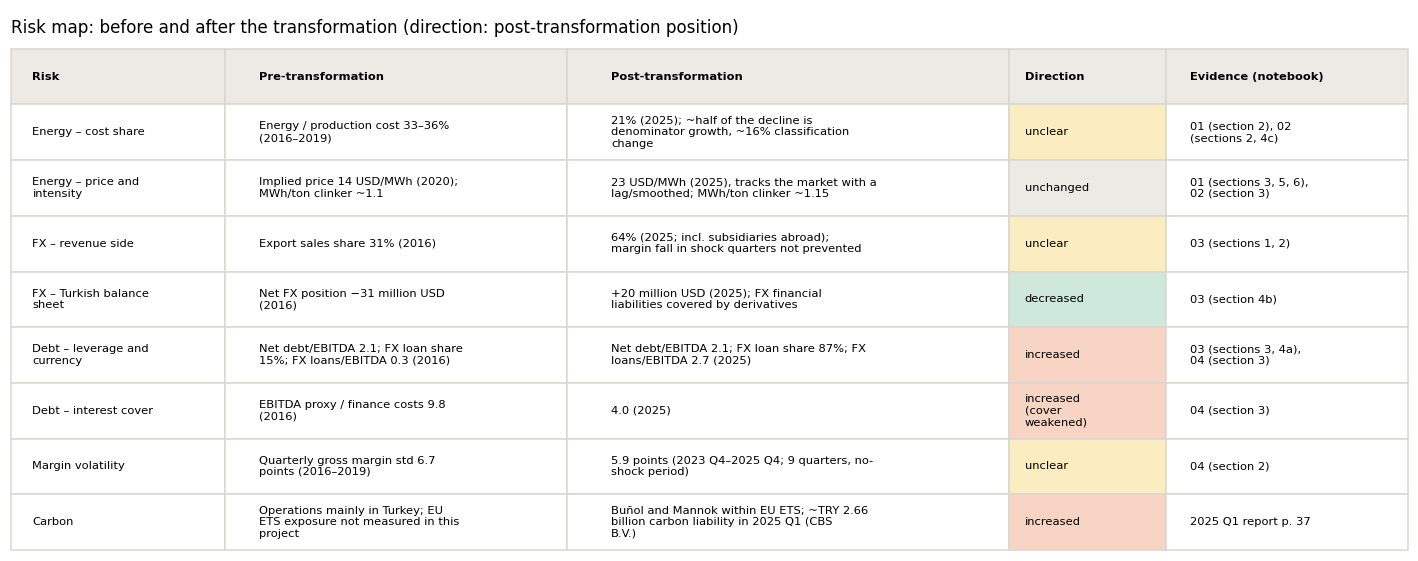

In [10]:
DIR_COL = {"decreased": "#cfe8dc", "increased": "#f8d4c4", "increased (cover weakened)": "#f8d4c4", "unchanged": "#eceae4", "unclear": "#fbecc2"}
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.axis("off")
import textwrap
cell_text = [[textwrap.fill(str(v), w) for v, w in zip([r] + list(row.values), [22, 34, 44, 14, 22])] for r, row in risk.iterrows()]
tbl = ax.table(cellText=cell_text, colLabels=["Risk"] + list(risk.columns), cellLoc="left", colLoc="left",
               colWidths=[0.15, 0.24, 0.31, 0.11, 0.17], bbox=[0, 0, 1, 0.93])
tbl.auto_set_font_size(False); tbl.set_fontsize(7.5)
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("#d9d7d0")
    if r == 0:
        cell.set_facecolor("#eceae4"); cell.set_text_props(weight="bold")
    elif c == 3:
        cell.set_facecolor(DIR_COL.get(risk.iloc[r - 1]["Direction"], "white"))
ax.text(0, 0.985, "Risk map: before and after the transformation (direction: post-transformation position)", fontsize=11, transform=ax.transAxes, va="top")
fig.tight_layout()
fig.savefig(FIGS / "04_risk_map.png", bbox_inches="tight")
plt.show()

**What we see:**
- **Decreasing risk:** FX risk on the Turkish balance sheet.
- **Increasing risk:** FX debt and the weakening of interest cover; carbon exposure (2025 Q1 report, CBS B.V. carbon liability).
- **Unclear or unchanged:** No clear reduction in risk can be shown on the energy side (price and physical intensity); margin volatility is also unclear.

## 5. Conclusion

### H3 – volatility part: NOT REFUTED BUT CANNOT BE CONFIRMED (insufficient evidence)
- Post-transformation quarterly gross margin volatility (std 5.9 points) is slightly lower than pre-transformation (6.7) and slightly higher than in the crisis and transition period (5.3). The seasonally adjusted measure is similar (6.3 / 7.5 / 5.7).
- The differences are small. The post-transformation period is short at 9 quarters and contains no major shock; the small decline in volatility could also be explained by the absence of shocks.
- The "more FX-denominated" part of H3 is visible on the revenue side in notebook 03: the export sales share is 64%, but the definition widened after 2024. The margin part of H3 was confirmed in notebook 02.

### H4: PARTIALLY
- *Confirmed – part of the risk has shifted to borrowing:*
  - FX loans / EBITDA proxy 0.3 → 2.7x.
  - FX loan share 15% → 87%.
  - Interest cover 9.8 → 4.0x.
  - Overall leverage (net debt / EBITDA proxy 2.1) is close to 2016, but its composition has shifted to FX.
- *Partially confirmed – more resilient to FX:*
  - FX risk on the Turkish balance sheet decreased (from a net FX liability to a net FX asset).
  - At group level FX debt is 0.75x export sales.
  - However, the margin fall in shock quarters was not prevented.
- *Not supported – more resilient to energy:*
  - Exposure to the energy price and physical energy intensity did not change markedly.
  - The fall in the energy share comes mainly together with denominator growth, lower prices and the classification change.
- *Success criterion (FX revenue covering FX debt):*
  - In 2025 FX loans are 0.75x annual export sales.
  - The real test is the full-year cash flow of the foreign companies that carry the debt (Mannok, SBS). This cannot be measured with outside-in data.

**Finding from notebook 05 (price and unit cost):** Within the cement segment, two periods were decomposed inside the same IAS 29 series. In 2022r → 2023, the period with the margin jump (11.5% → 20.4%), gross profit per ton rose by +7.6 USD: roughly +14.2 USD from lower energy cost, −5.1 USD from revenue per ton (real), and −1.4 USD from other unit costs. This coincides with the reconstruction year after the 6 February 2023 earthquakes; yet in the same year Çimsa's revenue per ton declined in real terms. In 2023 → 2025 gross profit per ton was almost unchanged (+0.4 USD/ton: revenue −2.1, energy +5.5, other cost −3.0); the cement PPI also fell in real terms in 2024–2025. In both periods the margin improvement comes mainly together with the market-driven fall in energy cost; there is no improvement in the unit costs under the company's control. The large increase in other costs in the 2022 nominal → 2025 comparison arises in the IAS 29 and SBS-inclusive restatement of 2022; it is not operational. This finding is consistent with the assessment that the "more resilient to energy shocks" part of H4 is not supported: the margin remains dependent on the energy price.

### Hypotheses to be verified with internal data (limits of the outside-in analysis)
- **Energy contracts:** Structure, maturity, price formula and hedging; the source of the lag/smoothing pattern in the implied price (01).
- **Fuel and electricity prices:** The actual petcoke purchase price and the cost per GJ of alternative fuels; the coal index is only an approximate indicator. Çimsa's actual electricity purchase price instead of the PTF.
- **Segment energy cost:** Energy cost and physical consumption by segment; direct measurement of the mix effect on the energy share (02).
- **Mannok full year:** Full-year performance, debt service and EU ETS cost; the year-end energy classification shift in 2024 Q4 (10).
- **Carbon:** Breakdown by plant of the carbon liability (2025 Q1 ~TRY 2.66 billion; attributed to CBS B.V. in the report) and the size of the annual carbon cost.
- **Quarterly FX revenue share:** Path of the revenue mix in shock quarters (03).
- **FX sensitivity:** Disproportionate to the net position in 2023–2024; intra-group loans need to be separated (03).
- **Inconsistencies within reports:** 2019 inter-segment transfer pricing and the 2023 cement production figure (02).